# 07 — Hyperparameter tuning (LightGBM and XGBoost)

Finds good settings for the two tree models, using the **training** cohorts to learn and the **validation** cohorts
to judge. The test set is **not** touched.

**Why these two models:** both are gradient-boosted trees. They find non-straight patterns (for example, capital
matters differently in each sector), handle empty values, and are the usual best choice for tables like ours. Both
are tried because neither is always better.

**How:** `RandomizedSearchCV` tries `N_TRIES` random combinations of settings per model. Each one learns on the
training cohorts and is scored (PR-AUC) on the validation cohorts. This is a **time** split, not random folds,
so every score is "how well it predicts newer businesses" (`PredefinedSplit`).

**Reads:** `pipeline/05_model_table.parquet`, `06_baseline_results.csv`.
**Saves:** `pipeline/07_best_params.json`, `07_tuning_results.csv`.

**The notebooks, in order** (each one loads what the one before saved, so nothing is downloaded or read from Excel twice):

| # | Notebook | Saves (in `Darb DataSets/pipeline`) |
|---|---|---|
| 00 | `00_download` | `00_raw/`: an exact copy of every raw file, as fast parquet |
| 01 | `01_eda_raw` | `01_quarter_quality.csv`: how complete each MC quarter is |
| 02 | `02_preprocess_businesses` | `02_businesses.parquet`: one row per business, with its label |
| 03 | `03_preprocess_economic` | `03_*.parquet`: GDP, SME, SAMA and licensing features |
| 04 | `04_eda_clean` | nothing (looks only) |
| 05 | `05_features` | `05_model_table.parquet`: the model's inputs and the time split |
| 06 | `06_baseline` | `06_baseline_results.csv` |
| 07 | `07_tuning` | `07_best_params.json`, `07_tuning_results.csv` |
| 08 | `08_final_training` | `models/`: the final model and its report |

**Rules:** raw files are never changed · nothing is dropped (problems get a flag) · data never goes into Git ·
clear all outputs before committing.

### Setup
Finds the data folder. **Locally** it is `~/darb-data` (or the folder in the `DARB_DATA` setting), a copy of the
team's Drive folder **Darb DataSets**. **On Colab** it is Darb DataSets itself: add a shortcut to it in your My
Drive first, and upload the files of `ml/src` to `/content`.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    !pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from model_tools import fis, fis_band, make_model, make_preprocessor, scores

table = pd.read_parquet(need(PIPE / '05_model_table.parquet', '05_features'))
spec = json.loads((PIPE / '05_features.json').read_text())
CATEGORICAL, NUMERIC, TARGET = spec['categorical'], spec['numeric'], spec['target']
INPUTS = CATEGORICAL + NUMERIC
for column in CATEGORICAL:
    table[column] = table[column].astype(object).where(table[column].notna(), np.nan)
parts = {name: table[table['split'] == name] for name in ['train', 'validation', 'test']}
X = {name: part[INPUTS] for name, part in parts.items()}
y = {name: part[TARGET].to_numpy() for name, part in parts.items()}
pd.set_option('display.width', 200)
print({name: f'{len(part):,} rows, {y[name].mean():.1%} failed' for name, part in parts.items()})

{'train': '89,800 rows, 17.2% failed', 'validation': '93,949 rows, 8.5% failed', 'test': '76,547 rows, 12.3% failed'}


In [3]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

N_TRIES = 20
X_search = pd.concat([X['train'], X['validation']])
y_search = np.concatenate([y['train'], y['validation']])
time_split = PredefinedSplit(np.r_[np.full(len(y['train']), -1), np.zeros(len(y['validation']), dtype=int)])
ratio = (y['train'] == 0).sum() / (y['train'] == 1).sum()      # survived per failed, for XGBoost's weight
print(f'Search rows: {len(y_search):,} | survived per failed in training: {ratio:.1f}')

Search rows: 183,749 | survived per failed in training: 4.8


## 1 — The settings tried

| Setting | What it controls |
|---|---|
| `n_estimators` | number of trees |
| `learning_rate` | how much each tree corrects the ones before (smaller = slower, often better) |
| `num_leaves` / `max_depth` | how detailed each tree can be |
| `min_child_samples` / `min_child_weight` | the fewest businesses a leaf may describe (bigger = less over-fitting) |
| `subsample`, `colsample_bytree` | each tree sees a random part of the rows / inputs (less over-fitting) |
| `reg_lambda` | a penalty on extreme values |
| `class_weight` / `scale_pos_weight` | extra weight on the rare failed businesses, or none |

In [4]:
SEARCHES = {
    'LightGBM': (
        make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=False),
                   LGBMClassifier(subsample_freq=1, verbose=-1, random_state=42)),
        {'model__n_estimators': randint(200, 1200), 'model__learning_rate': loguniform(0.01, 0.2),
         'model__num_leaves': randint(15, 255), 'model__min_child_samples': randint(20, 500),
         'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.5, 0.5),
         'model__reg_lambda': loguniform(1e-3, 10), 'model__class_weight': [None, 'balanced']}),
    'XGBoost': (
        make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=False),
                   XGBClassifier(tree_method='hist', eval_metric='aucpr', random_state=42)),
        {'model__n_estimators': randint(200, 1200), 'model__learning_rate': loguniform(0.01, 0.2),
         'model__max_depth': randint(3, 10), 'model__min_child_weight': loguniform(1, 50),
         'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.5, 0.5),
         'model__reg_lambda': loguniform(1e-2, 10), 'model__scale_pos_weight': [1.0, ratio]}),
}

## 2 — Search
This is the slow cell (about ten to thirty minutes). The best settings of each model are printed.

In [5]:
import time

best_params, tries = {}, []
for name, (pipeline, space) in SEARCHES.items():
    started = time.time()
    search = RandomizedSearchCV(pipeline, space, n_iter=N_TRIES, scoring='average_precision', cv=time_split,
                                refit=False, random_state=42, n_jobs=1)
    search.fit(X_search, y_search)
    best_params[name] = {k.replace('model__', ''): (v.item() if hasattr(v, 'item') else v) for k, v in search.best_params_.items()}
    found = pd.DataFrame(search.cv_results_)[['params', 'mean_test_score']].assign(model=name)
    tries.append(found)
    print(f'{name}: best validation PR-AUC {search.best_score_:.4f} ({time.time() - started:.0f} s)')
    print('   ', best_params[name])
tries = pd.concat(tries, ignore_index=True).rename(columns={'mean_test_score': 'validation PR-AUC'})

LightGBM: best validation PR-AUC 0.1841 (311 s)
    {'class_weight': 'balanced', 'colsample_bytree': 0.9692763545078751, 'learning_rate': 0.010023356974647664, 'min_child_samples': 463, 'n_estimators': 476, 'num_leaves': 175, 'reg_lambda': 0.016480446427978974, 'subsample': 0.8099025726528951}


XGBoost: best validation PR-AUC 0.1854 (39 s)
    {'colsample_bytree': 0.5909124836035503, 'learning_rate': 0.017322667470546258, 'max_depth': 6, 'min_child_weight': 10.944108064793868, 'n_estimators': 452, 'reg_lambda': 0.19762189340280073, 'scale_pos_weight': 1.0, 'subsample': 0.8099098641033556}


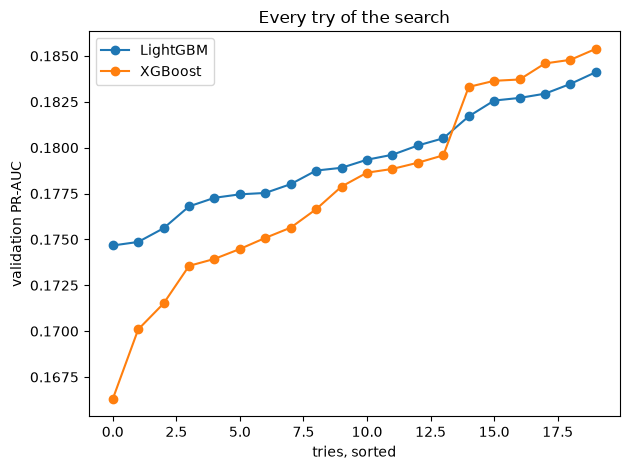

In [6]:
for name, part in tries.groupby('model'):
    plt.plot(sorted(part['validation PR-AUC']), marker='o', label=name)
plt.ylabel('validation PR-AUC'); plt.xlabel('tries, sorted'); plt.title('Every try of the search'); plt.legend()
plt.tight_layout(); plt.show()

## 3 — The tuned models against the baseline (validation)
Each tuned model learns again on the training cohorts with its best settings, and gets all the scores.

In [7]:
CLASSES = {'LightGBM': LGBMClassifier, 'XGBoost': XGBClassifier}
FIXED = {'LightGBM': dict(subsample_freq=1, verbose=-1, random_state=42),
         'XGBoost': dict(tree_method='hist', eval_metric='aucpr', random_state=42)}
results = pd.read_csv(need(PIPE / '06_baseline_results.csv', '06_baseline'), index_col='model')
for name, params in best_params.items():
    model = make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=False), CLASSES[name](**FIXED[name], **params))
    model.fit(X['train'], y['train'])
    results.loc[f'{name} (tuned)'] = scores(y['validation'], model.predict_proba(X['validation'])[:, 1])
results.round(4)

,PR-AUC,ROC-AUC,recall (failed),precision (failed),Brier,failure rate
model,,,,,,
always the average,0.0850,0.5000,0.0000,0.0000,0.0853,0.085
logistic regression,0.1886,0.7696,0.7065,0.1719,0.1430,0.085
LightGBM (tuned),0.1841,0.7588,0.8576,0.1629,0.1552,0.085
XGBoost (tuned),0.1854,0.7585,0.0039,0.4079,0.0736,0.085


## Save

In [8]:
(PIPE / '07_best_params.json').write_text(json.dumps(best_params, indent=2))
results.to_csv(PIPE / '07_tuning_results.csv', index_label='model')
tries.assign(params=tries['params'].astype(str)).to_csv(PIPE / '07_all_tries.csv', index=False)
print('Saved', PIPE / '07_best_params.json', 'and', PIPE / '07_tuning_results.csv')

Saved /Users/halaalsabbar/darb-data/pipeline/07_best_params.json and /Users/halaalsabbar/darb-data/pipeline/07_tuning_results.csv
